# Chương 3 bài 2 AutoViz trên Marketing Campaign

**Nguồn:** Lab EDA, mục 1.3.4, trang 18

**Đề bài:** Tìm hiểu tính năng, cách sử dụng AutoViz và áp dụng trên Marketing Campaign.

Code triển khai bài tập theo dữ liệu đã cung cấp; không phải đoạn chép nguyên văn bài mẫu.

In [1]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data').is_dir() and (p / 'README.md').is_file())
DATA = ROOT / 'data'
OUT = ROOT / 'ket_qua' / 'C3_BT02_AutoViz_Marketing'
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'figure.figsize': (8, 4)})

def save_fig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140, bbox_inches='tight')
    plt.show()

def save_summary(values):
    (OUT / 'tom_tat.json').write_text(
        json.dumps(values, ensure_ascii=False, indent=2), encoding='utf-8'
    )


## 1 Chuẩn bị dữ liệu

In [2]:
marketing = pd.read_csv(DATA / 'marketing_campaign.csv', sep=None, engine='python')
print('Shape:', marketing.shape)
print('Missing values:', marketing.isna().sum()[marketing.isna().any()].to_dict())
print('Response:', marketing['Response'].value_counts().to_dict())
# Historical ages are referenced to the latest customer-registration year.
joined = pd.to_datetime(marketing['Dt_Customer'], dayfirst=True, errors='coerce')
reference_year = int(joined.dt.year.max())
marketing['Age_at_reference'] = reference_year - marketing['Year_Birth']
marketing['Customer_Join_Year'] = joined.dt.year
marketing = marketing.drop(columns=['ID', 'Dt_Customer'])
constant_cols = [c for c in marketing if marketing[c].nunique(dropna=False) <= 1]
marketing = marketing.drop(columns=constant_cols)
print('Reference year:', reference_year)
print('Constant columns excluded:', constant_cols)
print('Age > 100 (flag for review):', int((marketing['Age_at_reference'] > 100).sum()))
# Preserve missing Income and outliers for EDA diagnostics, not automatic deletion.

Shape: (2240, 29)
Missing values: {'Income': 24}
Response: {0: 1906, 1: 334}
Reference year: 2014
Constant columns excluded: ['Z_CostContact', 'Z_Revenue']
Age > 100 (flag for review): 3


## 2 Sinh biểu đồ bằng AutoViz

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
Shape of your Data Set loaded: (2240, 27)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
  Printing up to 30 columns (max) in each category:
    Numeric Columns : ['Income']
    Integer-Categorical Columns: ['Year_Birth', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'Nu

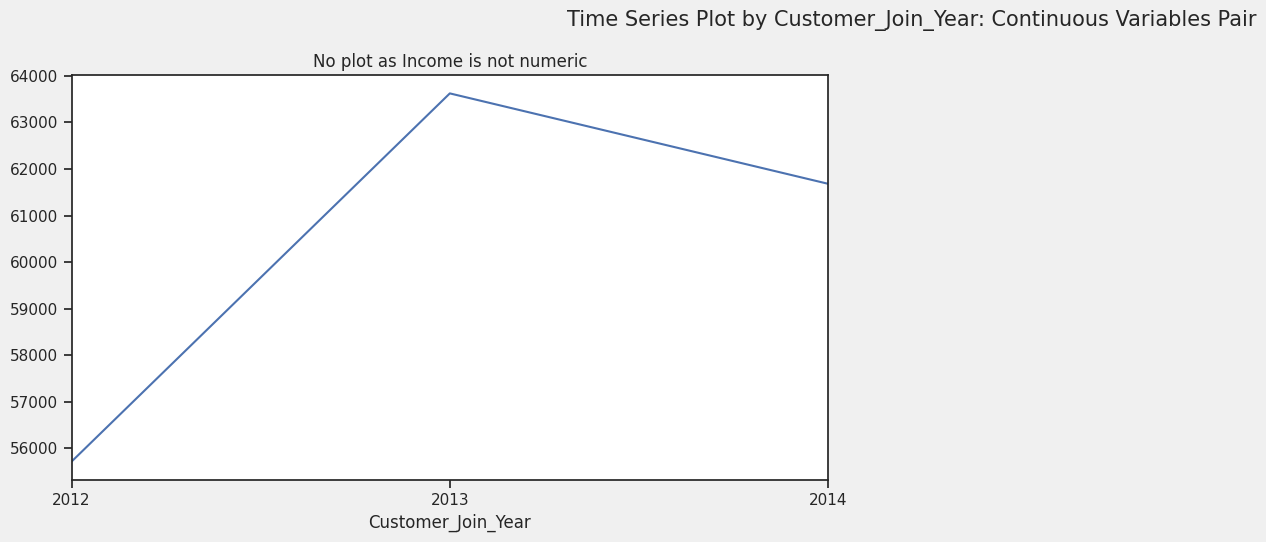

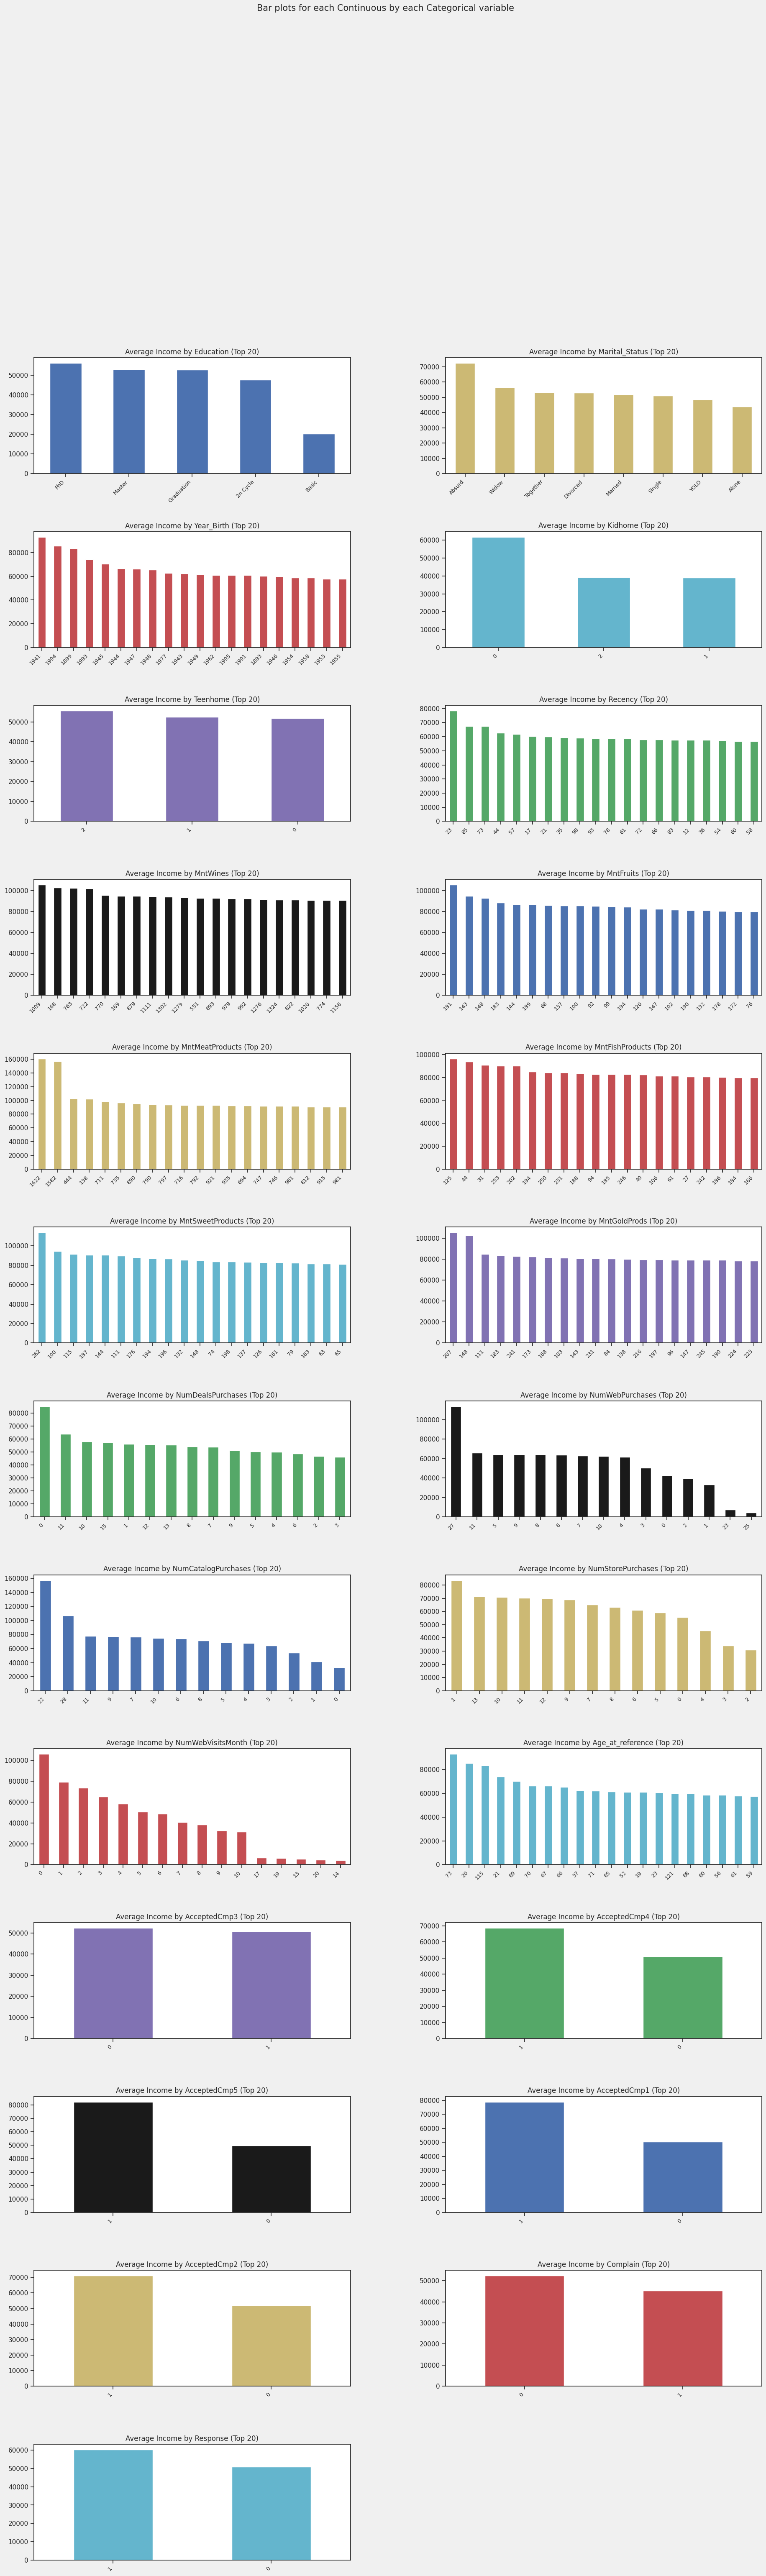

In [3]:
from autoviz.AutoViz_Class import AutoViz_Class
AV = AutoViz_Class()
result = AV.AutoViz(
    filename='', dfte=marketing.copy(), depVar='Response',
    header=0, verbose=2, lowess=False, chart_format='svg',
    max_rows_analyzed=150000, max_cols_analyzed=40,
    save_plot_dir=str(OUT / 'AutoViz_Plots')
)
files = sorted((OUT / 'AutoViz_Plots').rglob('*'))
charts = [p for p in files if p.is_file()]
print('Generated files:', len(charts))
for path in charts:
    print(path.relative_to(OUT))
if not charts:
    raise RuntimeError('AutoViz did not save charts. Check the execution output.')
save_summary({'rows':len(marketing), 'input_columns':marketing.shape[1],
              'reference_year':reference_year,
              'missing_income':int(marketing.Income.isna().sum()),
              'response_rate':float(marketing.Response.mean()),
              'generated_files':[str(p.relative_to(OUT)) for p in charts]})

## Nhận xét và giới hạn
AutoViz tự nhận diện biến và tạo biểu đồ thống kê/quan hệ theo Response. verbose=2 và chart_format=svg dùng để lưu hình. Giới hạn 150000 dòng và 40 cột lớn hơn tập đầu vào, nên không chủ động cắt mẫu ở notebook. Công cụ có thể tự xử lý/loại một số cột hoặc thiếu dữ liệu; xem log và đối chiếu dữ liệu gốc. Tham khảo: https://github.com/AutoViML/AutoViz